# Balanced + Feature-Augmented NSL-KDD — GRU, Five-Seed Final Evaluation

## 1. Environment and reproducibility


In [ ]:
# Global reproducibility setup
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("Global seed set to:", SEED)


In [2]:
import pandas as pd
import numpy as np
import sklearn, os
from sklearn.preprocessing import StandardScaler # RobustScaler
import matplotlib.pyplot as plt  # for plotting
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve, auc
from tensorflow.keras.optimizers import Adam

from sklearn.preprocessing import LabelEncoder
import seaborn as sns 
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import time


## 2. Data preprocessing and feature augmentation

The cells below retain the original preprocessing order and diagnostic outputs.


### Directly clean Augmented data 


In [3]:
# ============================================================
# Load the pre-generated NSL-KDD augmented partitions
# ============================================================
from pathlib import Path

# Change only this directory if the three CSV files are elsewhere.
AUGMENTED_DATA_DIRECTORY = (
    Path.cwd()
    / "/kaggle/input/datasets/zerukifle/nsl-kdd-major-review"
)

TRAIN_FILE = (
    AUGMENTED_DATA_DIRECTORY
    / "NSL_KDD_Augmented_Train.csv"
)

VALIDATION_FILE = (
    AUGMENTED_DATA_DIRECTORY
    / "NSL_KDD_Augmented_Validation.csv"
)

TEST_FILE = (
    AUGMENTED_DATA_DIRECTORY
    / "NSL_KDD_Augmented_Test.csv"
)

for file_path in [
    TRAIN_FILE,
    VALIDATION_FILE,
    TEST_FILE,
]:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required augmented partition not found: {file_path.resolve()}"
        )

train_data = pd.read_csv(TRAIN_FILE)
validation_data = pd.read_csv(VALIDATION_FILE)
test_data = pd.read_csv(TEST_FILE)



# ============================================================
# Verify the pre-generated NSL-KDD split proportions
# ============================================================
if train_data.empty:
    raise ValueError("The training dataset is empty.")

if validation_data.empty:
    raise ValueError("The validation dataset is empty.")

if test_data.empty:
    raise ValueError("The test dataset is empty.")

print(f"Training data:   {train_data.shape}")
print(f"Validation data: {validation_data.shape}")
print(f"Test data:       {test_data.shape}")


print(f"Training data:   {train_data.shape}")
print(f"Validation data: {validation_data.shape}")
print(f"Test data:       {test_data.shape}")


display(train_data.head())

Training data:   (104258, 44)
Validation data: (14826, 44)
Test data:       (29433, 44)
Training data:   (104258, 44)
Validation data: (14826, 44)
Test data:       (29433, 44)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,IF_Anomaly_Score,AE_Anomaly_Score,SUOD_Anomaly_Score,category
0,0.0,1.0,11.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.00,0.00,1.0,1.0,0.00,0.0,-0.409113,0.008093,-0.155286,DoS
1,0.0,1.0,49.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.00,0.00,0.0,0.0,1.00,1.0,-0.455302,0.095445,0.259301,DoS
2,0.0,1.0,20.0,9.0,172.0,0.0,0.0,0.0,0.0,0.0,...,0.18,0.00,0.4,0.0,0.02,0.0,-0.421444,0.086396,-0.270910,Normal
3,0.0,1.0,24.0,9.0,233.0,547.0,0.0,0.0,0.0,0.0,...,0.03,0.03,0.0,0.0,0.00,0.0,-0.361821,0.009765,-0.623136,Normal
4,0.0,1.0,24.0,9.0,330.0,453.0,0.0,0.0,0.0,0.0,...,0.01,0.02,0.0,0.0,0.00,0.0,-0.347595,0.004767,-0.797096,Normal


In [4]:
# ============================================================
# Validate dataset + select reusable feature-ablation mode
# ============================================================

LABEL_COLUMN = "category"

ANOMALY_FEATURES = [
    "IF_Anomaly_Score",
    "AE_Anomaly_Score",
    "SUOD_Anomaly_Score",
]

# Change ONLY this line for another feature configuration.
#
# "Full_FA"   -> original features + IF + AE + SUOD
# "No_FA"     -> original features only
# "IF_only"   -> original features + IF
# "AE_only"   -> original features + AE
# "SUOD_only" -> original features + SUOD
ABLATION_MODE = "Full_FA"


# ============================================================
# Validate the originally loaded augmented partitions
# ============================================================

for dataset_name, dataset in {
    "Training": train_data,
    "Validation": validation_data,
    "Test": test_data,
}.items():

    if LABEL_COLUMN not in dataset.columns:
        raise KeyError(
            f"'{LABEL_COLUMN}' was not found in the "
            f"{dataset_name} dataset."
        )

    missing_anomaly_features = [
        feature
        for feature in ANOMALY_FEATURES
        if feature not in dataset.columns
    ]

    if missing_anomaly_features:
        raise KeyError(
            f"{dataset_name} dataset is missing "
            f"the following anomaly-score features: "
            f"{missing_anomaly_features}"
        )


# ============================================================
# Select anomaly-score features to remove
# ============================================================

if ABLATION_MODE == "Full_FA":
    features_to_drop = []

elif ABLATION_MODE == "No_FA":
    features_to_drop = [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "IF_only":
    features_to_drop = [
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "AE_only":
    features_to_drop = [
        "IF_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "SUOD_only":
    features_to_drop = [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
    ]

else:
    raise ValueError(
        f"Unknown ABLATION_MODE: {ABLATION_MODE}. "
        "Use Full_FA, No_FA, IF_only, AE_only, or SUOD_only."
    )


# ============================================================
# Apply selected feature configuration
# ============================================================

train_data = train_data.drop(
    columns=features_to_drop
).copy()

validation_data = validation_data.drop(
    columns=features_to_drop
).copy()

test_data = test_data.drop(
    columns=features_to_drop
).copy()


# ============================================================
# Rebuild and validate feature order
# ============================================================

feature_columns = [
    column
    for column in train_data.columns
    if column != LABEL_COLUMN
]

validation_feature_columns = [
    column
    for column in validation_data.columns
    if column != LABEL_COLUMN
]

test_feature_columns = [
    column
    for column in test_data.columns
    if column != LABEL_COLUMN
]

if feature_columns != validation_feature_columns:
    raise ValueError(
        "Training and validation feature columns/order do not match."
    )

if feature_columns != test_feature_columns:
    raise ValueError(
        "Training and test feature columns/order do not match."
    )

kept_anomaly_features = [
    feature
    for feature in ANOMALY_FEATURES
    if feature in feature_columns
]

expected_kept_features = {
    "Full_FA": [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ],
    "No_FA": [],
    "IF_only": ["IF_Anomaly_Score"],
    "AE_only": ["AE_Anomaly_Score"],
    "SUOD_only": ["SUOD_Anomaly_Score"],
}

if kept_anomaly_features != expected_kept_features[ABLATION_MODE]:
    raise ValueError(
        "The retained anomaly-score features do not match "
        f"the selected mode '{ABLATION_MODE}'. "
        f"Found: {kept_anomaly_features}"
    )

print("=" * 60)
print("Balanced NSL-KDD feature-ablation configuration")
print("=" * 60)
print(f"Ablation mode: {ABLATION_MODE}")
print(f"Number of input features: {len(feature_columns)}")
print(f"Kept anomaly-score features: {kept_anomaly_features}")
print(f"Dropped anomaly-score features: {features_to_drop}")
print(f"Training instances before SMOTE: {len(train_data):,}")
print(f"Validation instances: {len(validation_data):,}")
print(f"Test instances: {len(test_data):,}")
print("=" * 60)


Balanced NSL-KDD feature-ablation configuration
Ablation mode: Full_FA
Number of input features: 43
Kept anomaly-score features: ['IF_Anomaly_Score', 'AE_Anomaly_Score', 'SUOD_Anomaly_Score']
Dropped anomaly-score features: []
Training instances before SMOTE: 104,258
Validation instances: 14,826
Test instances: 29,433


### Separate augmented features and multiclass labels


In [5]:
# import numpy as np

# from sklearn.preprocessing import LabelEncoder


# ============================================================
# Extract augmented feature matrices
# ============================================================
# feature_columns were defined in the validation cell.
# Selecting these columns preserves the training column order.
X_train = train_data[
    feature_columns
].copy()

X_val = validation_data[
    feature_columns
].copy()

X_test = test_data[
    feature_columns
].copy()


# ============================================================
# Validate numeric feature values
# ============================================================
for dataset_name, feature_data in {
    "Training": X_train,
    "Validation": X_val,
    "Test": X_test
}.items():

    non_numeric_columns = feature_data.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    if non_numeric_columns:
        raise TypeError(
            f"{dataset_name} data contain non-numeric "
            f"features: {non_numeric_columns}"
        )

    if not np.isfinite(
        feature_data.to_numpy(dtype=np.float32)
    ).all():
        raise ValueError(
            f"{dataset_name} features contain missing "
            "or infinite values."
        )


# ============================================================
# Extract original multiclass labels
# ============================================================
y_train_original = (
    train_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_val_original = (
    validation_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_test_original = (
    test_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)


print(f"Training features:   {X_train.shape}")
print(f"Validation features: {X_val.shape}")
print(f"Test features:       {X_test.shape}")

print(
    f"\nNumber of training classes: "
    f"{y_train_original.nunique()}"
)

display(y_train_original.value_counts())


Training features:   (104258, 43)
Validation features: (14826, 43)
Test features:       (29433, 43)

Number of training classes: 5


category
Normal    54091
DoS       37477
Probe      9882
R2L        2724
U2R          84
Name: count, dtype: int64

#### Encode the multiclass labels


In [6]:
# ============================================================
# Fit the label encoder on training labels only
# ============================================================
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(
    y_train_original
)


# ============================================================
# Check for unknown validation or test classes
# ============================================================
training_classes = set(
    label_encoder.classes_
)

unknown_validation_classes = (
    set(y_val_original.unique())
    - training_classes
)

unknown_test_classes = (
    set(y_test_original.unique())
    - training_classes
)

if unknown_validation_classes:
    raise ValueError(
        "Validation data contain classes that are absent "
        f"from training: {sorted(unknown_validation_classes)}"
    )

if unknown_test_classes:
    raise ValueError(
        "Test data contain classes that are absent "
        f"from training: {sorted(unknown_test_classes)}"
    )


# Transform validation and test labels using the same encoder
y_val = label_encoder.transform(
    y_val_original
)

y_test = label_encoder.transform(
    y_test_original
)


# ============================================================
# Display multiclass mapping
# ============================================================
print("Multiclass label mapping:")

for class_code, class_name in enumerate(
    label_encoder.classes_
):
    print(f"{class_code}: {class_name}")


number_of_classes = len(
    label_encoder.classes_
)

print(
    f"\nNumber of multiclass target classes: "
    f"{number_of_classes}"
)


# ============================================================
# Verify the expected five NSL-KDD multiclass categories
# ============================================================
expected_nsl_kdd_classes = {
    "normal",
    "dos",
    "probe",
    "r2l",
    "u2r",
}

observed_nsl_kdd_classes = {
    str(class_name).strip().lower()
    for class_name in label_encoder.classes_
}

if number_of_classes != 5:
    raise ValueError(
        "NSL-KDD must contain five multiclass categories, but "
        f"{number_of_classes} were found."
    )

if observed_nsl_kdd_classes != expected_nsl_kdd_classes:
    raise ValueError(
        "Unexpected NSL-KDD category names. "
        f"Observed: {label_encoder.classes_.tolist()}"
    )

print("NSL-KDD five-class target validation completed successfully.")


Multiclass label mapping:
0: DoS
1: Normal
2: Probe
3: R2L
4: U2R

Number of multiclass target classes: 5
NSL-KDD five-class target validation completed successfully.


#### Balance the U2R training class only

SMOTE is applied only to the encoded U2R class in the training partition. Validation and test partitions remain unchanged. Resampling is performed before standardization, preserving the balanced-pipeline preprocessing order.


In [7]:
# ============================================================
# U2R-only SMOTE on the unstandardized training partition
# ============================================================
from collections import Counter
from imblearn.over_sampling import SMOTE


# Confirm that encoded class 4 is U2R before applying the
# dataset-specific NSL-KDD sampling strategy.
u2r_class_codes = [
    class_code
    for class_code, class_name in enumerate(label_encoder.classes_)
    if str(class_name).strip().lower() == "u2r"
]

if len(u2r_class_codes) != 1:
    raise ValueError(
        "Exactly one U2R class was expected, but the encoded mapping was: "
        f"{label_encoder.classes_.tolist()}"
    )

U2R_CLASS_CODE = int(u2r_class_codes[0])

if U2R_CLASS_CODE != 4:
    raise ValueError(
        "The NSL-KDD balancing protocol expects U2R to be encoded as class 4. "
        f"Observed U2R code: {U2R_CLASS_CODE}"
    )


# Define the desired number of instances per class after resampling:
# raise U2R from 84 training instances by 2,620 synthetic instances.
target_class_counts = {
    4: 84 + 2620
}


training_distribution_before_smote = Counter(
    map(int, y_train)
)

u2r_training_count = int(
    training_distribution_before_smote[U2R_CLASS_CODE]
)

if u2r_training_count != 84:
    raise ValueError(
        "The fixed NSL-KDD split is expected to contain 84 U2R training "
        f"instances before SMOTE, but {u2r_training_count} were found. "
        "Check that the intended NSL-KDD augmented partitions are being used."
    )

if target_class_counts[U2R_CLASS_CODE] <= u2r_training_count:
    raise ValueError(
        "The U2R SMOTE target must be greater than the original U2R count."
    )


# Apply SMOTE to the training partition only.
smote = SMOTE(
    sampling_strategy=target_class_counts,
    random_state=42,
)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train,
    y_train,
)

X_train_resampled = np.asarray(
    X_train_resampled,
    dtype=np.float32,
)

y_train_resampled = np.asarray(
    y_train_resampled,
    dtype=y_train.dtype,
)


print(
    "Original training class distribution: "
    f"{training_distribution_before_smote}"
)

print(
    "Resampled training class distribution: "
    f"{Counter(map(int, y_train_resampled))}"
)

print(
    f"U2R target count: "
    f"{target_class_counts[U2R_CLASS_CODE]}"
)

print(
    f"Resampled training features: "
    f"{X_train_resampled.shape}"
)

print(
    f"Unchanged validation features: "
    f"{X_val.shape}"
)

print(
    f"Unchanged test features: "
    f"{X_test.shape}"
)


Original training class distribution: Counter({1: 54091, 0: 37477, 2: 9882, 3: 2724, 4: 84})
Resampled training class distribution: Counter({1: 54091, 0: 37477, 2: 9882, 3: 2724, 4: 2704})
U2R target count: 2704
Resampled training features: (106878, 43)
Unchanged validation features: (14826, 43)
Unchanged test features: (29433, 43)


#### Standardize the data

The scaler is fitted only on the SMOTE-resampled training features and is applied unchanged to validation and test data.


In [8]:
from sklearn.preprocessing import StandardScaler


# ============================================================
# Fit the scaler on the SMOTE-resampled training features only
# ============================================================
classifier_scaler = StandardScaler()

X_train_scaled = classifier_scaler.fit_transform(
    X_train_resampled
).astype(np.float32)


# Apply the same fitted scaler without refitting.
# Validation and test instances retain their original distributions.
X_val_scaled = classifier_scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = classifier_scaler.transform(
    X_test
).astype(np.float32)


# ============================================================
# Verify scaled data and aligned training labels
# ============================================================
if len(X_train_scaled) != len(y_train_resampled):
    raise ValueError(
        "Scaled training features and resampled labels are misaligned."
    )

for dataset_name, feature_data in {
    "Training": X_train_scaled,
    "Validation": X_val_scaled,
    "Test": X_test_scaled,
}.items():
    if not np.isfinite(feature_data).all():
        raise ValueError(
            f"Scaled {dataset_name.lower()} features contain invalid values."
        )


print(
    f"Scaled resampled training features: "
    f"{X_train_scaled.shape}"
)

print(
    f"Scaled validation features: "
    f"{X_val_scaled.shape}"
)

print(
    f"Scaled test features: "
    f"{X_test_scaled.shape}"
)

print(
    f"\nResampled training mean after scaling: "
    f"{X_train_scaled.mean():.6f}"
)

print(
    f"Resampled training standard deviation after scaling: "
    f"{X_train_scaled.std():.6f}"
)


Scaled resampled training features: (106878, 43)
Scaled validation features: (14826, 43)
Scaled test features: (29433, 43)

Resampled training mean after scaling: 0.000000
Resampled training standard deviation after scaling: 1.000000


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


## 3. Gated Recurrent Unit Network (GRU)

### Prepare the GRU input representation

The original GRU input-variable names are retained.


In [9]:
# Preserve the original one-time-step representation, using scaled inputs.
input_attribute_count = X_train_scaled.shape[1]

X_train_reshaped_GRU = X_train_scaled.reshape(
    -1, 1, input_attribute_count
)
X_val_reshaped_GRU = X_val_scaled.reshape(
    -1, 1, input_attribute_count
)
X_test_reshaped_GRU = X_test_scaled.reshape(
    -1, 1, input_attribute_count
)

print(f"GRU training shape:   {X_train_reshaped_GRU.shape}")
print(f"GRU validation shape: {X_val_reshaped_GRU.shape}")
print(f"GRU test shape:       {X_test_reshaped_GRU.shape}")


GRU training shape:   (106878, 1, 43)
GRU validation shape: (14826, 1, 43)
GRU test shape:       (29433, 1, 43)


### Optional GRU hyperparameter optimization

- Keep `RUN_OPTUNA = False` for the current 5-seed final experiment.
  The previously stored optimized GRU parameters are loaded.
- Change `RUN_OPTUNA = True` only when you want to perform a new
  hyperparameter search.

The optimization uses the training and validation partitions only.
The test partition is not used for hyperparameter selection.


In [10]:
# ============================================================
# GRU optimization control
# ============================================================

import json

# Recommended ablation protocol:
# - Run Optuna once under Full_FA.
# - Reuse the selected hyperparameters for No_FA, IF_only,
#   AE_only, and SUOD_only so the ablation isolates the
#   contribution of the anomaly-score features.
RUN_OPTUNA = True

N_OPTUNA_TRIALS = 25

MAX_EPOCHS_GRU = 100
EARLY_STOPPING_PATIENCE = 10

PARAMETER_DIRECTORY = (
    Path("/kaggle/working")
    / "NSL_KDD_Balanced_Optimized_Parameters"
)

PARAMETER_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

BEST_PARAMS_GRU_FILE = (
    PARAMETER_DIRECTORY
    / "best_params_gru_balanced_NSL_KDD.json"
)

if RUN_OPTUNA and ABLATION_MODE != "Full_FA":
    raise ValueError(
        "For the feature-ablation study, run Optuna under "
        "ABLATION_MODE='Full_FA' and reuse the resulting "
        "hyperparameters for the other modes by setting "
        "RUN_OPTUNA=False."
    )

print(f"RUN_OPTUNA = {RUN_OPTUNA}")
print(f"ABLATION_MODE = {ABLATION_MODE}")
print(f"N_OPTUNA_TRIALS = {N_OPTUNA_TRIALS}")
print(f"MAX_EPOCHS_GRU = {MAX_EPOCHS_GRU}")

print(
    "GRU parameter file:",
    BEST_PARAMS_GRU_FILE.resolve(),
)


RUN_OPTUNA = True
ABLATION_MODE = Full_FA
N_OPTUNA_TRIALS = 25
MAX_EPOCHS_GRU = 100
GRU parameter file: /kaggle/working/NSL_KDD_Balanced_Optimized_Parameters/best_params_gru_balanced_NSL_KDD.json


In [11]:
from sklearn.metrics import f1_score
from tensorflow.keras import regularizers
from tensorflow.keras.layers import (
    GRU,
    Dense,
    Dropout,
    Input,
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam


class SparseMacroF1(tf.keras.metrics.Metric):
    """Dataset-level macro F1 for sparse integer multiclass labels."""

    def __init__(
        self,
        number_of_classes,
        name="macro_f1",
        **kwargs,
    ):
        super().__init__(
            name=name,
            **kwargs,
        )

        self.number_of_classes = int(
            number_of_classes
        )

        self.confusion_matrix = self.add_weight(
            name="confusion_matrix",
            shape=(
                self.number_of_classes,
                self.number_of_classes,
            ),
            initializer="zeros",
            dtype=tf.float32,
        )

    def update_state(
        self,
        y_true,
        y_pred,
        sample_weight=None,
    ):
        y_true = tf.cast(
            tf.reshape(
                y_true,
                [-1],
            ),
            tf.int32,
        )

        y_pred = tf.argmax(
            y_pred,
            axis=1,
            output_type=tf.int32,
        )

        weights = None

        if sample_weight is not None:
            weights = tf.cast(
                tf.reshape(
                    sample_weight,
                    [-1],
                ),
                tf.float32,
            )

        batch_confusion_matrix = (
            tf.math.confusion_matrix(
                y_true,
                y_pred,
                num_classes=(
                    self.number_of_classes
                ),
                weights=weights,
                dtype=tf.float32,
            )
        )

        self.confusion_matrix.assign_add(
            batch_confusion_matrix
        )

    def result(self):
        true_positives = (
            tf.linalg.diag_part(
                self.confusion_matrix
            )
        )

        false_positives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=0,
            )
            - true_positives
        )

        false_negatives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=1,
            )
            - true_positives
        )

        class_f1 = tf.math.divide_no_nan(
            2.0 * true_positives,
            2.0 * true_positives
            + false_positives
            + false_negatives,
        )

        return tf.reduce_mean(
            class_f1
        )

    def reset_state(self):
        self.confusion_matrix.assign(
            tf.zeros_like(
                self.confusion_matrix
            )
        )

    def get_config(self):
        config = super().get_config()

        config.update(
            {
                "number_of_classes":
                    self.number_of_classes
            }
        )

        return config


In [12]:
# ============================================================
# Updated GRU Optuna objective and search space
# ============================================================

def objective_gru(trial):
    """Train one balanced-NSL-KDD GRU trial and return validation macro F1."""

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(
        SEED + trial.number
    )

    hidden_layer1_gru = trial.suggest_int(
        "hidden_layer1_gru",
        32,
        128,
        step=16,
    )

    hidden_layer2_gru = trial.suggest_int(
        "hidden_layer2_gru",
        16,
        64,
        step=16,
    )

    dropout_rate_gru = trial.suggest_float(
        "dropout_rate_gru",
        0.1,
        0.4,
        step=0.1,
    )

    l2_reg = trial.suggest_float(
        "l2_reg",
        1e-6,
        1e-3,
        log=True,
    )

    batch_size_gru = trial.suggest_categorical(
        "batch_size_gru",
        [64, 128, 256],
    )

    learning_rate_gru = trial.suggest_float(
        "learning_rate_gru",
        1e-5,
        1e-2,
        log=True,
    )

    model_gru_trial = Sequential(
        [
            Input(
                shape=(
                    1,
                    input_attribute_count,
                )
            ),

            GRU(
                hidden_layer1_gru,
                return_sequences=True,
                kernel_regularizer=(
                    regularizers.l2(
                        l2_reg
                    )
                ),
            ),

            Dropout(
                dropout_rate_gru
            ),

            GRU(
                hidden_layer2_gru,
                return_sequences=False,
                kernel_regularizer=(
                    regularizers.l2(
                        l2_reg
                    )
                ),
            ),

            Dropout(
                dropout_rate_gru
            ),

            Dense(
                number_of_classes,
                activation="softmax",
                kernel_regularizer=(
                    regularizers.l2(
                        l2_reg
                    )
                ),
            ),
        ],
        name="GRU_Optuna_Trial",
    )

    model_gru_trial.compile(
        loss="sparse_categorical_crossentropy",

        optimizer=Adam(
            learning_rate=(
                learning_rate_gru
            )
        ),

        metrics=[
            "accuracy",
            SparseMacroF1(
                number_of_classes
            ),
        ],
    )

    early_stopping = (
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=EARLY_STOPPING_PATIENCE,
            restore_best_weights=True,
        )
    )

    model_gru_trial.fit(
        X_train_reshaped_GRU,
        y_train_resampled,

        epochs=MAX_EPOCHS_GRU,

        batch_size=batch_size_gru,

        validation_data=(
            X_val_reshaped_GRU,
            y_val,
        ),

        callbacks=[
            early_stopping,

            KerasPruningCallback(
                trial,
                monitor="val_macro_f1",
                interval=1,
            ),
        ],

        shuffle=True,
        verbose=0,
    )

    validation_probabilities = (
        model_gru_trial.predict(
            X_val_reshaped_GRU,
            verbose=0,
        )
    )

    validation_predictions = np.argmax(
        validation_probabilities,
        axis=1,
    )

    validation_macro_f1 = f1_score(
        y_val,
        validation_predictions,
        labels=np.arange(
            number_of_classes
        ),
        average="macro",
        zero_division=0,
    )

    del model_gru_trial
    tf.keras.backend.clear_session()

    return float(
        validation_macro_f1
    )


In [14]:
# !pip install optuna-integration[keras]

In [15]:
# ============================================================
# Execute optional Optuna optimization
# ============================================================

if RUN_OPTUNA:

    import optuna
    from optuna.trial import TrialState

    # Current Optuna versions provide integrations through
    # optuna-integration. The fallback supports older versions.
    try:
        from optuna_integration import (
            KerasPruningCallback
        )
    except ImportError:
        from optuna.integration import (
            KerasPruningCallback
        )

    # TPE sampling and median-based early pruning.
    study_gru = optuna.create_study(
        direction="maximize",
        sampler=(
            optuna.samplers.TPESampler(
                seed=SEED
            )
        ),
        pruner=(
            optuna.pruners.MedianPruner(
                n_startup_trials=5,
                n_warmup_steps=10,
                interval_steps=1,
            )
        ),
    )

    study_gru.optimize(
        objective_gru,
        n_trials=N_OPTUNA_TRIALS,
        n_jobs=1,
        gc_after_trial=True,
    )

    complete_trials_gru = (
        study_gru.get_trials(
            deepcopy=False,
            states=[
                TrialState.COMPLETE
            ],
        )
    )

    pruned_trials_gru = (
        study_gru.get_trials(
            deepcopy=False,
            states=[
                TrialState.PRUNED
            ],
        )
    )

    failed_trials_gru = (
        study_gru.get_trials(
            deepcopy=False,
            states=[
                TrialState.FAIL
            ],
        )
    )

    print(
        "Best GRU hyperparameters:",
        study_gru.best_params,
    )

    print(
        "Best GRU validation macro F1: "
        f"{study_gru.best_value:.6f}"
    )

    print(
        "GRU study statistics:"
    )

    print(
        "  Number of finished trials:",
        len(
            study_gru.trials
        ),
    )

    print(
        "  Number of complete trials:",
        len(
            complete_trials_gru
        ),
    )

    print(
        "  Number of pruned trials:",
        len(
            pruned_trials_gru
        ),
    )

    print(
        "  Number of failed trials:",
        len(
            failed_trials_gru
        ),
    )

    best_trial_gru = (
        study_gru.best_trial
    )

    print(
        "  Best validation macro F1: "
        f"{best_trial_gru.value:.6f}"
    )

    print(
        "  Best parameters:"
    )

    for (
        key,
        value,
    ) in best_trial_gru.params.items():
        print(
            f"    {key}: {value}"
        )

    # Preserve the original variable name.
    best_params_gru_03_TVTF_SUDO_V3 = (
        study_gru.best_params
    )

    with open(
        BEST_PARAMS_GRU_FILE,
        "w",
        encoding="utf-8",
    ) as json_file:
        json.dump(
            best_params_gru_03_TVTF_SUDO_V3,
            json_file,
            indent=2,
        )


    study_gru.trials_dataframe().to_csv(
        PARAMETER_DIRECTORY
        / "gru_optuna_trial_history_NSL_KDD.csv",
        index=False,
    )

    print(
        "New optimized GRU parameters saved to:",
        BEST_PARAMS_GRU_FILE,
    )

else:
    print(
        "Optuna optimization skipped. "
        "Using the pre-stored GRU parameters."
    )


[I 2026-09-29 11:25:21,235] A new study created in memory with name: no-name-6a5caa06-2c15-4807-8008-c56f38d26d12
2026-09-29 11:25:21.523970: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
[I 2026-09-29 11:32:22,416] Trial 0 finished with value: 0.8784968159538753 and parameters: {'hidden_layer1_gru': 64, 'hidden_layer2_gru': 64, 'dropout_rate_gru': 0.30000000000000004, 'l2_reg': 6.251373574521755e-05, 'batch_size_gru': 64, 'learning_rate_gru': 0.003967605077052989}. Best is trial 0 with value: 0.8784968159538753.
[I 2026-09-29 11:44:41,629] Trial 1 finished with value: 0.8060805076631488 and parameters: {'hidden_layer1_gru': 96, 'hidden_layer2_gru': 48, 'dropout_rate_gru': 0.1, 'l2_reg': 0.0008123245085588687, 'batch_size_gru': 64, 'learning_rate_gru': 3.5498788321965036e-05}. Best is trial 0 with value: 0.8784968159538753.
[I 2026-09-29 11:55:10,387] Trial 2 finished with value

Best GRU hyperparameters: {'hidden_layer1_gru': 112, 'hidden_layer2_gru': 32, 'dropout_rate_gru': 0.2, 'l2_reg': 2.457139693916716e-06, 'batch_size_gru': 64, 'learning_rate_gru': 0.0028655324457127805}
Best GRU validation macro F1: 0.923903
GRU study statistics:
  Number of finished trials: 25
  Number of complete trials: 18
  Number of pruned trials: 7
  Number of failed trials: 0
  Best validation macro F1: 0.923903
  Best parameters:
    hidden_layer1_gru: 112
    hidden_layer2_gru: 32
    dropout_rate_gru: 0.2
    l2_reg: 2.457139693916716e-06
    batch_size_gru: 64
    learning_rate_gru: 0.0028655324457127805
New optimized GRU parameters saved to: /kaggle/working/NSL_KDD_Balanced_Optimized_Parameters/best_params_gru_balanced_NSL_KDD.json


### Load the optimized GRU parameters for final training

- With `RUN_OPTUNA = False`, it loads the existing pre-stored JSON.
- With `RUN_OPTUNA = True`, it loads the newly optimized JSON saved above.


In [16]:
import json

# Load the optimized parameters used by final GRU training.

if not BEST_PARAMS_GRU_FILE.is_file():
    raise FileNotFoundError(
        f"Optimized GRU parameter file not found: "
        f"{BEST_PARAMS_GRU_FILE.resolve()}. "
        "Set RUN_OPTUNA=True under ABLATION_MODE='Full_FA' "
        "and run the optimization cell first."
    )

with open(
    BEST_PARAMS_GRU_FILE,
    "r",
    encoding="utf-8",
) as json_file:

    loaded_parameters = json.load(
        json_file
    )

best_params_gru_03 = loaded_parameters.get(
    "best_params",
    loaded_parameters,
)

required_gru_parameters = {
    "hidden_layer1_gru",
    "hidden_layer2_gru",
    "dropout_rate_gru",
    "l2_reg",
    "batch_size_gru",
    "learning_rate_gru",
}

missing_gru_parameters = (
    required_gru_parameters
    - set(best_params_gru_03)
)

if missing_gru_parameters:
    raise KeyError(
        "The selected GRU parameter file is missing: "
        f"{sorted(missing_gru_parameters)}"
    )

print(
    "GRU parameters loaded for final training:"
)

best_params_gru_03


GRU parameters loaded for final training:


{'hidden_layer1_gru': 112,
 'hidden_layer2_gru': 32,
 'dropout_rate_gru': 0.2,
 'l2_reg': 2.457139693916716e-06,
 'batch_size_gru': 64,
 'learning_rate_gru': 0.0028655324457127805}

## 4. Five-run final training and journal reporting

In [17]:
from pathlib import Path
import gc

from tensorflow.keras import regularizers
from tensorflow.keras.layers import GRU, Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    matthews_corrcoef,
    multilabel_confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)


# ============================================================
# Repeated-run protocol
# ============================================================
RUN_SEEDS = [42, 43, 44, 45, 46]
N_FINAL_RUNS = len(RUN_SEEDS)

N_WARMUP_RUNS = 3
N_BENCHMARK_RUNS = 5

REPORT_OUTPUT_DIRECTORY = (
    Path("/kaggle/working")
    / f"NSL_KDD_Balanced_{ABLATION_MODE}_GRU_5_seed_V2"
)

# Keep the original variable name for compatibility.
# Each GRU_Seed_* folder is created directly inside this directory.
MODEL_OUTPUT_DIRECTORY = REPORT_OUTPUT_DIRECTORY

REPORT_OUTPUT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)


def set_final_run_seed(seed):
    """Reset Python, NumPy, and TensorFlow random states for one run."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


# Request deterministic TensorFlow kernels when supported.
try:
    tf.config.experimental.enable_op_determinism()
    print("TensorFlow deterministic operations enabled.")
except (AttributeError, RuntimeError):
    print(
        "TensorFlow deterministic-operation control is unavailable "
        "in this environment."
    )


def benchmark_full_test_prediction(model, X_input):
    """Return probabilities and timing from the original inference protocol."""
    warmup_size = min(1024, len(X_input))

    for _ in range(N_WARMUP_RUNS):
        model.predict(
            X_input[:warmup_size],
            verbose=0,
        )

    measured_times = []
    probabilities = None

    for _ in range(N_BENCHMARK_RUNS):
        start_time = time.perf_counter()

        probabilities = model.predict(
            X_input,
            verbose=0,
        )

        measured_times.append(
            time.perf_counter() - start_time
        )

    mean_inference_time = float(
        np.mean(measured_times)
    )

    return (
        probabilities,
        {
            "Inference_Time_s": mean_inference_time,

            "Latency_ms_per_sample": (
                mean_inference_time
                / len(X_input)
                * 1000.0
            ),

            "Throughput_samples_per_s": (
                len(X_input)
                / mean_inference_time
            ),
        },
        measured_times,
    )


def calculate_fpr_metrics(y_true, y_pred, labels):
    """Calculate macro, micro/overall, and support-weighted multiclass FPR."""
    matrices = multilabel_confusion_matrix(
        y_true,
        y_pred,
        labels=labels,
    )

    per_class_fpr = []
    false_positives = []
    true_negatives = []

    for matrix in matrices:
        true_negative, false_positive, _, _ = matrix.ravel()

        denominator = (
            false_positive + true_negative
        )

        per_class_fpr.append(
            false_positive / denominator
            if denominator
            else 0.0
        )

        false_positives.append(
            false_positive
        )
        true_negatives.append(
            true_negative
        )

    per_class_fpr = np.asarray(
        per_class_fpr,
        dtype=float,
    )
    false_positives = np.asarray(
        false_positives,
        dtype=float,
    )
    true_negatives = np.asarray(
        true_negatives,
        dtype=float,
    )

    supports = np.asarray(
        [
            (y_true == label).sum()
            for label in labels
        ],
        dtype=float,
    )

    micro_denominator = (
        false_positives.sum()
        + true_negatives.sum()
    )

    return {
        "FPR_macro": float(
            per_class_fpr.mean()
        ),
        "FPR_micro_overall": float(
            false_positives.sum()
            / micro_denominator
            if micro_denominator
            else 0.0
        ),
        "FPR_weighted": float(
            np.average(
                per_class_fpr,
                weights=supports,
            )
        ),
    }


def calculate_test_metrics(
    y_true,
    y_pred,
    probabilities,
    labels,
):
    """Calculate scalar test metrics for one independent GRU training run."""
    metrics = {
        "Accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "Precision_macro": precision_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "Recall_macro": recall_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "F1_macro": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "Precision_weighted": precision_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "Recall_weighted": recall_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "F1_weighted": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "MCC": matthews_corrcoef(
            y_true,
            y_pred,
        ),
    }

    try:
        metrics["ROC_AUC_macro_OvR"] = roc_auc_score(
            y_true,
            probabilities,
            labels=labels,
            average="macro",
            multi_class="ovr",
        )
    except ValueError as error:
        metrics["ROC_AUC_macro_OvR"] = np.nan
        print(
            f"Macro ROC-AUC could not be calculated: {error}"
        )

    metrics.update(
        calculate_fpr_metrics(
            y_true,
            y_pred,
            labels,
        )
    )

    return metrics


def format_mean_sd(mean_value, sd_value):
    """Create the journal-table mean ± sample-SD representation."""
    if pd.isna(mean_value):
        return "NA"

    if pd.isna(sd_value):
        return f"{mean_value:.6f} ± NA"

    return (
        f"{mean_value:.6f} ± "
        f"{sd_value:.6f}"
    )


def plot_publication_confusion_matrix(
    y_true,
    y_pred,
    output_stem,
):
    """Save confusion matrix as PDF and 600-dpi PNG."""
    matrix = confusion_matrix(
        y_true,
        y_pred,
    )

    plt.figure(
        figsize=(6.8, 5.5)
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
    )

    plt.xticks(
        rotation=45,
        ha="right",
        fontsize=10,
    )
    plt.yticks(
        rotation=45,
        fontsize=10,
    )
    plt.xlabel(
        "Predicted Label",
        fontsize=11,
    )
    plt.ylabel(
        "True Label",
        fontsize=11,
    )
    plt.tight_layout()

    plt.savefig(
        f"{output_stem}.pdf",
        bbox_inches="tight",
    )
    plt.savefig(
        f"{output_stem}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()


TensorFlow deterministic operations enabled.


In [18]:
# ============================================================
# Save reproducibility artifacts for offline GRU inference
# ============================================================

import joblib
import platform
import sys
import sklearn

joblib.dump(
    classifier_scaler,
    REPORT_OUTPUT_DIRECTORY
    / "classifier_scaler.joblib",
)

with open(
    REPORT_OUTPUT_DIRECTORY
    / "feature_columns.json",
    "w",
    encoding="utf-8",
) as json_file:

    json.dump(
        list(feature_columns),
        json_file,
        indent=2,
    )

with open(
    REPORT_OUTPUT_DIRECTORY
    / "class_names.json",
    "w",
    encoding="utf-8",
) as json_file:

    json.dump(
        label_encoder.classes_.tolist(),
        json_file,
        indent=2,
    )

np.save(
    REPORT_OUTPUT_DIRECTORY
    / "X_test_model_input.npy",
    X_test_reshaped_GRU,
)

np.save(
    REPORT_OUTPUT_DIRECTORY
    / "y_test.npy",
    y_test,
)

with open(
    REPORT_OUTPUT_DIRECTORY
    / "selected_hyperparameters.json",
    "w",
    encoding="utf-8",
) as json_file:

    json.dump(
        best_params_gru_03,
        json_file,
        indent=2,
    )

environment_metadata = {
    "Dataset":
        "NSL-KDD",

    "Dataset_Setting":
        "Balanced training (U2R-only SMOTE)",

    "Model":
        "GRU",

    "Ablation_Mode":
        ABLATION_MODE,

    "Kept_Anomaly_Features":
        kept_anomaly_features,

    "Dropped_Anomaly_Features":
        features_to_drop,

    "Python":
        sys.version,

    "TensorFlow":
        tf.__version__,

    "NumPy":
        np.__version__,

    "Pandas":
        pd.__version__,

    "Scikit_learn":
        sklearn.__version__,

    "Platform":
        platform.platform(),

    "Processor":
        platform.processor(),

    "Machine":
        platform.machine(),

    "Visible_TensorFlow_Devices": [
        str(device)
        for device
        in tf.config.list_physical_devices()
    ],

    "Final_Run_Seeds":
        RUN_SEEDS,

    "Max_Epochs":
        MAX_EPOCHS_GRU,

    "Early_Stopping_Patience":
        EARLY_STOPPING_PATIENCE,

    "Warmup_Runs":
        N_WARMUP_RUNS,

    "Timed_Inference_Repetitions":
        N_BENCHMARK_RUNS,

    "Inference_Timing_Definition": (
        "Classifier prediction only; full test set; "
        "model loading and preprocessing excluded."
    ),
}

with open(
    REPORT_OUTPUT_DIRECTORY
    / "environment_metadata.json",
    "w",
    encoding="utf-8",
) as json_file:

    json.dump(
        environment_metadata,
        json_file,
        indent=2,
    )

print(
    "Saved balanced NSL-KDD GRU reproducibility artifacts to:",
    REPORT_OUTPUT_DIRECTORY.resolve(),
)


Saved balanced NSL-KDD GRU reproducibility artifacts to: /kaggle/working/NSL_KDD_Balanced_Full_FA_GRU_5_seed_V2


### Final GRU model builder

The original `build_final_gru(parameters)` function name and parameter keys are
retained.


In [20]:
def build_final_gru(parameters):
    model = Sequential(
        [
            Input(
                shape=(1, input_attribute_count)
            ),
            GRU(
                parameters["hidden_layer1_gru"],
                return_sequences=True,
                kernel_regularizer=regularizers.l2(
                    parameters["l2_reg"]
                ),
            ),
            Dropout(
                parameters["dropout_rate_gru"]
            ),
            GRU(
                parameters["hidden_layer2_gru"],
                return_sequences=False,
                kernel_regularizer=regularizers.l2(
                    parameters["l2_reg"]
                ),
            ),
            Dropout(
                parameters["dropout_rate_gru"]
            ),
            Dense(
                number_of_classes,
                activation="softmax",
                kernel_regularizer=regularizers.l2(
                    parameters["l2_reg"]
                ),
            ),
        ],
        name="GRU",
    )

    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(
            learning_rate=parameters[
                "learning_rate_gru"
            ]
        ),
        metrics=["accuracy"],
    )

    return model


### Execute five independent GRU runs


GRU: final run 1/5; seed=42
Epoch 1/100


2026-09-29 13:33:33.162334: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1668/1670 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9399 - loss: 0.2015

2026-09-29 13:33:46.230141: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1670/1670 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.9623 - loss: 0.1170 - val_accuracy: 0.9786 - val_loss: 0.0650
Epoch 2/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9777 - loss: 0.0667 - val_accuracy: 0.9835 - val_loss: 0.0503
Epoch 3/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9817 - loss: 0.0563 - val_accuracy: 0.9865 - val_loss: 0.0446
Epoch 4/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9838 - loss: 0.0508 - val_accuracy: 0.9875 - val_loss: 0.0430
Epoch 5/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9853 - loss: 0.0472 - val_accuracy: 0.9883 - val_loss: 0.0408
Epoch 6/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9861 - loss: 0.0443 - val_accuracy: 0.9881 - val_loss: 0.0417
Epoch 7/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9869 - loss: 0.0429 - val_accuracy: 0.9879 - val_loss: 0.0420
Epoch 8/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9872 - loss: 0.0427 - va

2026-09-29 13:40:18.625848: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-29 13:40:24.885996: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

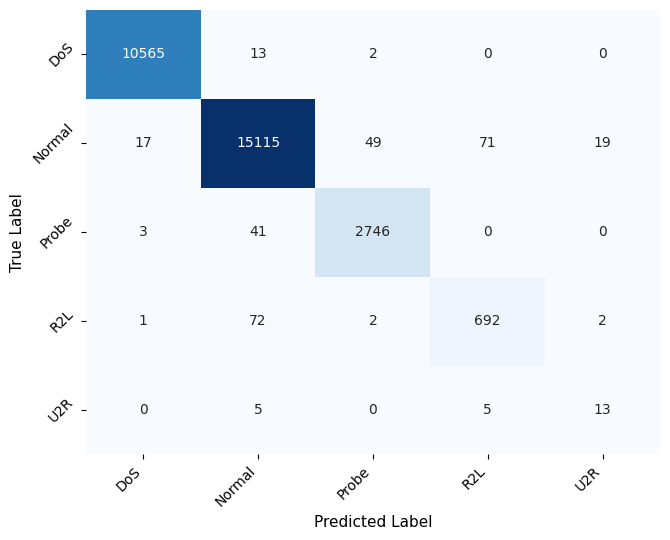

Completed GRU seed 42: test macro F1=0.865627
Saved run results to: /kaggle/working/NSL_KDD_Balanced_Full_FA_GRU_5_seed_V2/GRU_Seed_1

GRU: final run 2/5; seed=43
Epoch 1/100


2026-09-29 13:40:37.704787: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1664/1670 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9420 - loss: 0.2010

2026-09-29 13:40:49.880932: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1670/1670 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.9628 - loss: 0.1178 - val_accuracy: 0.9793 - val_loss: 0.0676
Epoch 2/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9776 - loss: 0.0654 - val_accuracy: 0.9836 - val_loss: 0.0548
Epoch 3/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9817 - loss: 0.0556 - val_accuracy: 0.9827 - val_loss: 0.0529
Epoch 4/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9839 - loss: 0.0502 - val_accuracy: 0.9844 - val_loss: 0.0474
Epoch 5/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9854 - loss: 0.0466 - val_accuracy: 0.9855 - val_loss: 0.0483
Epoch 6/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9863 - loss: 0.0453 - val_accuracy: 0.9866 - val_loss: 0.0443
Epoch 7/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9868 - loss: 0.0432 - val_accuracy: 0.9868 - val_loss: 0.0438
Epoch 8/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9876 - loss: 0.0410 - val

2026-09-29 13:48:00.468679: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-29 13:48:06.892701: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

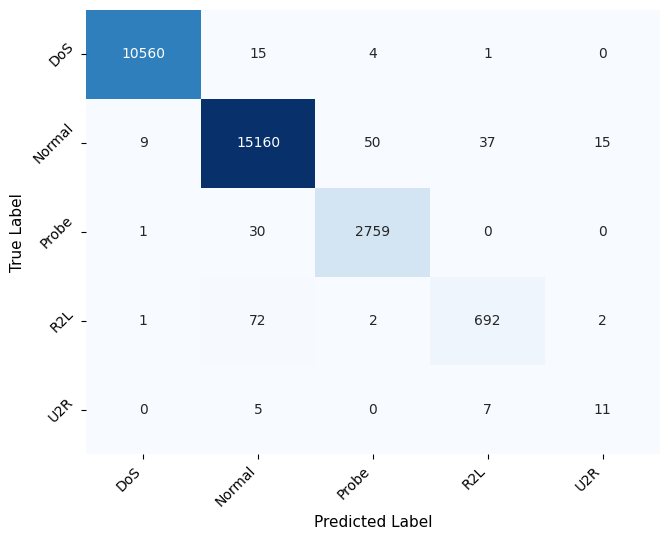

Completed GRU seed 43: test macro F1=0.865150
Saved run results to: /kaggle/working/NSL_KDD_Balanced_Full_FA_GRU_5_seed_V2/GRU_Seed_2

GRU: final run 3/5; seed=44
Epoch 1/100


2026-09-29 13:48:18.654576: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1662/1670 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9383 - loss: 0.2019

2026-09-29 13:48:31.071507: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1670/1670 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.9618 - loss: 0.1172 - val_accuracy: 0.9800 - val_loss: 0.0626
Epoch 2/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9783 - loss: 0.0654 - val_accuracy: 0.9825 - val_loss: 0.0545
Epoch 3/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9824 - loss: 0.0548 - val_accuracy: 0.9841 - val_loss: 0.0502
Epoch 4/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9840 - loss: 0.0495 - val_accuracy: 0.9855 - val_loss: 0.0467
Epoch 5/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9855 - loss: 0.0464 - val_accuracy: 0.9869 - val_loss: 0.0450
Epoch 6/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9863 - loss: 0.0441 - val_accuracy: 0.9873 - val_loss: 0.0451
Epoch 7/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9865 - loss: 0.0439 - val_accuracy: 0.9878 - val_loss: 0.0436
Epoch 8/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9875 - loss: 0.0414 - val

2026-09-29 13:57:28.921116: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-29 13:57:35.164313: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

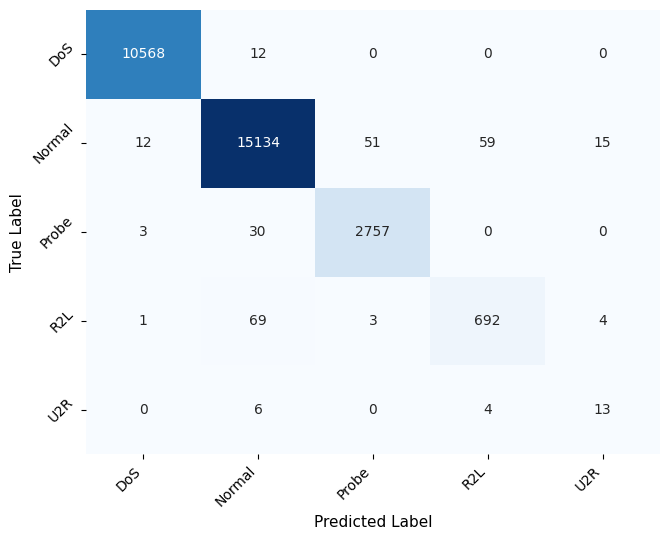

Completed GRU seed 44: test macro F1=0.871137
Saved run results to: /kaggle/working/NSL_KDD_Balanced_Full_FA_GRU_5_seed_V2/GRU_Seed_3

GRU: final run 4/5; seed=45
Epoch 1/100


2026-09-29 13:57:46.703926: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1662/1670 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9376 - loss: 0.2062

2026-09-29 13:57:58.864741: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1670/1670 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.9611 - loss: 0.1193 - val_accuracy: 0.9786 - val_loss: 0.0658
Epoch 2/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9777 - loss: 0.0661 - val_accuracy: 0.9831 - val_loss: 0.0517
Epoch 3/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9817 - loss: 0.0557 - val_accuracy: 0.9856 - val_loss: 0.0481
Epoch 4/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9843 - loss: 0.0494 - val_accuracy: 0.9860 - val_loss: 0.0485
Epoch 5/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9853 - loss: 0.0472 - val_accuracy: 0.9862 - val_loss: 0.0466
Epoch 6/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9864 - loss: 0.0442 - val_accuracy: 0.9881 - val_loss: 0.0438
Epoch 7/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9872 - loss: 0.0428 - val_accuracy: 0.9885 - val_loss: 0.0430
Epoch 8/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9877 - loss: 0.0414 - val

2026-09-29 14:01:37.178263: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-29 14:01:43.307077: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

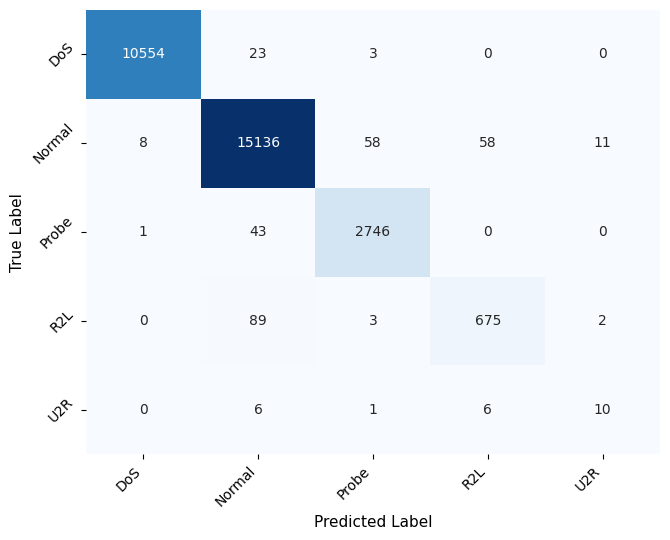

Completed GRU seed 45: test macro F1=0.859842
Saved run results to: /kaggle/working/NSL_KDD_Balanced_Full_FA_GRU_5_seed_V2/GRU_Seed_4

GRU: final run 5/5; seed=46
Epoch 1/100


2026-09-29 14:01:54.829113: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1661/1670 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9414 - loss: 0.1989

2026-09-29 14:02:07.096276: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1670/1670 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.9622 - loss: 0.1165 - val_accuracy: 0.9786 - val_loss: 0.0644
Epoch 2/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9780 - loss: 0.0656 - val_accuracy: 0.9813 - val_loss: 0.0535
Epoch 3/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9817 - loss: 0.0556 - val_accuracy: 0.9856 - val_loss: 0.0480
Epoch 4/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9839 - loss: 0.0503 - val_accuracy: 0.9853 - val_loss: 0.0454
Epoch 5/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9853 - loss: 0.0468 - val_accuracy: 0.9852 - val_loss: 0.0463
Epoch 6/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9859 - loss: 0.0446 - val_accuracy: 0.9851 - val_loss: 0.0445
Epoch 7/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9867 - loss: 0.0436 - val_accuracy: 0.9868 - val_loss: 0.0423
Epoch 8/100
1670/1670 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9868 - loss: 0.0424 - val

2026-09-29 14:05:44.723219: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-29 14:05:50.687146: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

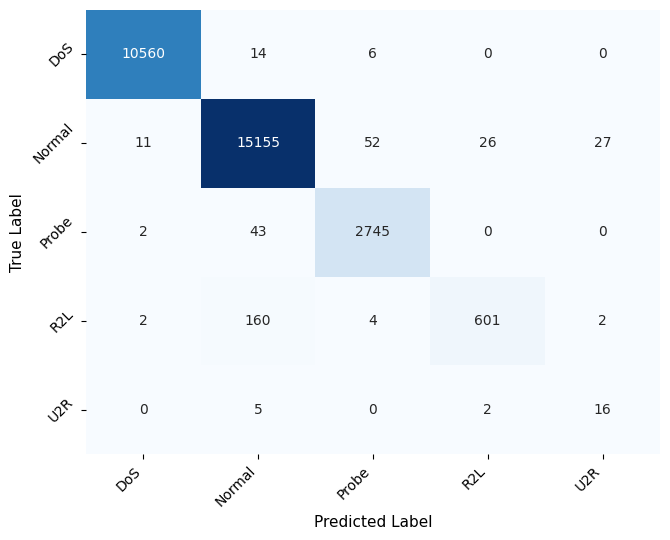

Completed GRU seed 46: test macro F1=0.859718
Saved run results to: /kaggle/working/NSL_KDD_Balanced_Full_FA_GRU_5_seed_V2/GRU_Seed_5


,Model,Run,Seed,Training_Time_s,Validation_F1_macro,Test_Loss,Accuracy,Precision_macro,Recall_macro,F1_macro,...,Recall_weighted,F1_weighted,MCC,ROC_AUC_macro_OvR,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Latency_ms_per_sample,Throughput_samples_per_s
0,GRU,1,42,405.508616,0.911075,0.042550,0.989739,0.850777,0.887537,0.865627,...,0.989739,0.989838,0.982677,0.994603,0.003144,0.002565,0.005458,1.936995,0.065810,15195.187643
1,GRU,2,43,442.803878,0.907817,0.039102,0.991472,0.860576,0.871572,0.865150,...,0.991472,0.991484,0.985592,0.997889,0.002690,0.002132,0.004920,1.959032,0.066559,15024.255405
2,GRU,3,44,550.324110,0.914476,0.039257,0.990861,0.858883,0.888631,0.871137,...,0.990861,0.990922,0.984568,0.997170,0.002796,0.002285,0.004842,1.901240,0.064596,15480.950021
3,GRU,4,45,230.505487,0.890403,0.041011,0.989400,0.862736,0.857096,0.859842,...,0.989400,0.989357,0.982085,0.997106,0.003392,0.002650,0.006360,1.885414,0.064058,15610.894955
4,GRU,5,46,229.951011,0.896631,0.042664,0.987905,0.854619,0.890314,0.859718,...,0.987905,0.987794,0.979541,0.997608,0.004152,0.003024,0.008666,1.801042,0.061191,16342.206401


In [21]:
def run_five_seed_experiment(
    model_name,
    model_builder,
    parameters,
    X_train_input,
    X_val_input,
    X_test_input,
    batch_size_key,
):
    """Train, evaluate, time, and save the GRU model for five seeds."""

    labels = np.arange(
        number_of_classes
    )

    run_rows = []
    per_class_rows = []
    representative_candidates = []

    for run_number, seed in enumerate(
        RUN_SEEDS,
        start=1,
    ):
        print(
            "\n" + "=" * 72
        )
        print(
            f"{model_name}: final run "
            f"{run_number}/{N_FINAL_RUNS}; "
            f"seed={seed}"
        )
        print(
            "=" * 72
        )

        # ----------------------------------------------------
        # Separate output folder for this independent run.
        # GRU_Seed_1 ... GRU_Seed_5
        # ----------------------------------------------------
        seed_output_directory = (
            MODEL_OUTPUT_DIRECTORY
            / f"GRU_Seed_{run_number}"
        )

        seed_output_directory.mkdir(
            parents=True,
            exist_ok=True,
        )

        tf.keras.backend.clear_session()
        set_final_run_seed(seed)

        model = model_builder(
            parameters
        )

        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------
        training_start = (
            time.perf_counter()
        )

        early_stopping = (
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
            )
        )

        history = model.fit(
            X_train_input,
            y_train_resampled,

            epochs=MAX_EPOCHS_GRU,

            batch_size=parameters[
                batch_size_key
            ],

            validation_data=(
                X_val_input,
                y_val,
            ),

            callbacks=[
                early_stopping
            ],

            shuffle=True,
            verbose=1,
        )

        training_time = (
            time.perf_counter()
            - training_start
        )

        # ----------------------------------------------------
        # Validation macro F1
        # ----------------------------------------------------
        validation_probabilities = (
            model.predict(
                X_val_input,
                verbose=0,
            )
        )

        validation_predictions = (
            np.argmax(
                validation_probabilities,
                axis=1,
            )
        )

        validation_macro_f1 = f1_score(
            y_val,
            validation_predictions,
            labels=labels,
            average="macro",
            zero_division=0,
        )

        # ----------------------------------------------------
        # Test evaluation and timing
        # ----------------------------------------------------
        evaluation = model.evaluate(
            X_test_input,
            y_test,
            verbose=0,
            return_dict=True,
        )

        (
            test_probabilities,
            timing_metrics,
            timing_repetitions,
        ) = benchmark_full_test_prediction(
            model,
            X_test_input,
        )

        pd.DataFrame(
            {
                "Repetition": np.arange(
                    1,
                    len(timing_repetitions) + 1,
                ),
                "Inference_Time_s":
                    timing_repetitions,
                "Latency_ms_per_sample": [
                    value
                    / len(X_test_input)
                    * 1000.0
                    for value
                    in timing_repetitions
                ],
            }
        ).to_csv(
            seed_output_directory
            / "inference_timing_repetitions.csv",
            index=False,
        )

        test_predictions = np.argmax(
            test_probabilities,
            axis=1,
        )

        test_metrics = calculate_test_metrics(
            y_test,
            test_predictions,
            test_probabilities,
            labels,
        )

        # ----------------------------------------------------
        # Scalar metrics
        # ----------------------------------------------------
        run_row = {
            "Model": model_name,
            "Run": run_number,
            "Seed": seed,
            "Training_Time_s": float(
                training_time
            ),
            "Validation_F1_macro": float(
                validation_macro_f1
            ),
            "Test_Loss": float(
                evaluation["loss"]
            ),
            **test_metrics,
            **timing_metrics,
        }

        run_rows.append(
            run_row
        )

        pd.DataFrame(
            [run_row]
        ).to_csv(
            seed_output_directory
            / "scalar_metrics.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Readable macro-only metrics.
        # ----------------------------------------------------
        macro_metrics_row = {
            "Model": run_row["Model"],
            "Run": run_row["Run"],
            "Seed": run_row["Seed"],
            "Precision_macro": run_row["Precision_macro"],
            "Recall_macro": run_row["Recall_macro"],
            "F1_macro": run_row["F1_macro"],
            "ROC_AUC_macro_OvR": run_row["ROC_AUC_macro_OvR"],
            "FPR_macro": run_row["FPR_macro"],
        }

        pd.DataFrame(
            [macro_metrics_row]
        ).to_csv(
            seed_output_directory
            / "macro_metrics.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Readable weighted-average metrics.
        # ----------------------------------------------------
        weighted_metrics_row = {
            "Model": run_row["Model"],
            "Run": run_row["Run"],
            "Seed": run_row["Seed"],
            "Precision_weighted": run_row["Precision_weighted"],
            "Recall_weighted": run_row["Recall_weighted"],
            "F1_weighted": run_row["F1_weighted"],
            "FPR_weighted": run_row["FPR_weighted"],
        }

        pd.DataFrame(
            [weighted_metrics_row]
        ).to_csv(
            seed_output_directory
            / "weighted_average_metrics.csv",
            index=False,
        )


        # ----------------------------------------------------
        # Full classification report
        # ----------------------------------------------------
        seed_classification_report = (
            classification_report(
                y_test,
                test_predictions,
                labels=labels,
                target_names=(
                    label_encoder.classes_
                ),
                output_dict=True,
                zero_division=0,
            )
        )

        pd.DataFrame(
            seed_classification_report
        ).transpose().to_csv(
            seed_output_directory
            / "classification_report.csv"
        )

        # ----------------------------------------------------
        # Per-class Precision / Recall / F1 / FPR
        # ----------------------------------------------------
        (
            precision_values,
            recall_values,
            f1_values,
            support_values,
        ) = precision_recall_fscore_support(
            y_test,
            test_predictions,
            labels=labels,
            zero_division=0,
        )

        class_confusion_matrices = (
            multilabel_confusion_matrix(
                y_test,
                test_predictions,
                labels=labels,
            )
        )

        seed_per_class_rows = []

        for (
            class_index,
            class_name,
        ) in enumerate(
            label_encoder.classes_
        ):
            (
                true_negative,
                false_positive,
                false_negative,
                true_positive,
            ) = class_confusion_matrices[
                class_index
            ].ravel()

            fpr_denominator = (
                false_positive
                + true_negative
            )

            class_fpr = (
                false_positive
                / fpr_denominator
                if fpr_denominator
                else 0.0
            )

            per_class_row = {
                "Model": model_name,
                "Run": run_number,
                "Seed": seed,
                "Class": class_name,
                "Precision": float(
                    precision_values[
                        class_index
                    ]
                ),
                "Recall": float(
                    recall_values[
                        class_index
                    ]
                ),
                "F1": float(
                    f1_values[
                        class_index
                    ]
                ),
                "FPR": float(
                    class_fpr
                ),
                "TP": int(
                    true_positive
                ),
                "TN": int(
                    true_negative
                ),
                "FP": int(
                    false_positive
                ),
                "FN": int(
                    false_negative
                ),
                "Support": int(
                    support_values[
                        class_index
                    ]
                ),
            }

            seed_per_class_rows.append(
                per_class_row
            )

            per_class_rows.append(
                per_class_row
            )

        pd.DataFrame(
            seed_per_class_rows
        ).to_csv(
            seed_output_directory
            / "per_class_metrics_and_fpr.csv",
            index=False,
        )

        # ----------------------------------------------------
        # FPR summary for this seed
        # ----------------------------------------------------
        pd.DataFrame(
            [
                {
                    "Model": model_name,
                    "Run": run_number,
                    "Seed": seed,
                    "FPR_macro": (
                        test_metrics[
                            "FPR_macro"
                        ]
                    ),
                    "FPR_micro_overall": (
                        test_metrics[
                            "FPR_micro_overall"
                        ]
                    ),
                    "FPR_weighted": (
                        test_metrics[
                            "FPR_weighted"
                        ]
                    ),
                }
            ]
        ).to_csv(
            seed_output_directory
            / "false_positive_rate_summary.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Confusion matrix: CSV + PDF + PNG
        # ----------------------------------------------------
        seed_confusion_matrix = (
            confusion_matrix(
                y_test,
                test_predictions,
                labels=labels,
            )
        )

        seed_confusion_matrix_df = (
            pd.DataFrame(
                seed_confusion_matrix,
                index=(
                    label_encoder.classes_
                ),
                columns=(
                    label_encoder.classes_
                ),
            )
        )

        seed_confusion_matrix_df.index.name = (
            "True_Label"
        )
        seed_confusion_matrix_df.columns.name = (
            "Predicted_Label"
        )

        seed_confusion_matrix_df.to_csv(
            seed_output_directory
            / "confusion_matrix.csv"
        )

        plot_publication_confusion_matrix(
            y_test,
            test_predictions,
            seed_output_directory
            / "confusion_matrix",
        )

        # ----------------------------------------------------
        # Training history
        # ----------------------------------------------------
        history_df = pd.DataFrame(
            history.history
        )

        history_df.index = (
            np.arange(
                1,
                len(history_df) + 1,
            )
        )
        history_df.index.name = (
            "Epoch"
        )

        history_df.to_csv(
            seed_output_directory
            / "training_history.csv"
        )

        # ----------------------------------------------------
        # Test predictions and probabilities
        # ----------------------------------------------------
        predictions_df = pd.DataFrame(
            {
                "True_Label_Encoded": (
                    y_test
                ),
                "Predicted_Label_Encoded": (
                    test_predictions
                ),
                "True_Label": (
                    label_encoder.inverse_transform(
                        y_test
                    )
                ),
                "Predicted_Label": (
                    label_encoder.inverse_transform(
                        test_predictions
                    )
                ),
            }
        )

        for (
            class_index,
            class_name,
        ) in enumerate(
            label_encoder.classes_
        ):
            predictions_df[
                f"Probability_{class_name}"
            ] = test_probabilities[
                :,
                class_index,
            ]

        predictions_df.to_csv(
            seed_output_directory
            / "test_predictions_and_probabilities.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Save trained model
        # ----------------------------------------------------
        model_path = (
            seed_output_directory
            / f"{model_name.lower()}_seed_{seed}.keras"
        )

        model.save(
            model_path
        )

        # ----------------------------------------------------
        # Save run metadata and exact pre-stored parameters
        # ----------------------------------------------------
        run_metadata = {
            "Model": model_name,
            "Run": run_number,
            "Seed": seed,
            "N_Final_Runs": N_FINAL_RUNS,
            "Training_Samples": int(
                len(X_train_input)
            ),
            "Validation_Samples": int(
                len(X_val_input)
            ),
            "Test_Samples": int(
                len(X_test_input)
            ),
            "Hyperparameters": parameters,

            "Ablation_Mode":
                ABLATION_MODE,

            "Kept_Anomaly_Features":
                kept_anomaly_features,

            "Dropped_Anomaly_Features":
                features_to_drop,

            "Training_Balancing":
                "U2R-only SMOTE",

            "Max_Epochs":
                MAX_EPOCHS_GRU,

            "Early_Stopping_Patience":
                EARLY_STOPPING_PATIENCE,

            "Warmup_Runs":
                N_WARMUP_RUNS,

            "Timed_Inference_Repetitions":
                N_BENCHMARK_RUNS,
        }

        with open(
            seed_output_directory
            / "run_metadata.json",
            "w",
            encoding="utf-8",
        ) as json_file:
            json.dump(
                run_metadata,
                json_file,
                indent=2,
            )

        representative_candidates.append(
            {
                "Seed": seed,
                "Run": run_number,
                "F1_macro": (
                    test_metrics[
                        "F1_macro"
                    ]
                ),
                "Predictions": (
                    test_predictions.copy()
                ),
            }
        )

        print(
            f"Completed {model_name} "
            f"seed {seed}: "
            f"test macro F1="
            f"{test_metrics['F1_macro']:.6f}"
        )

        print(
            "Saved run results to:",
            seed_output_directory.resolve(),
        )

        del history
        del model
        gc.collect()
        tf.keras.backend.clear_session()

    return (
        pd.DataFrame(
            run_rows
        ),
        pd.DataFrame(
            per_class_rows
        ),
        representative_candidates,
    )


# ============================================================
# GRU-only experiment definition
# Keep the original experiment-definition variable name.
# ============================================================
experiment_definitions = [
    {
        "model_name": "GRU",
        "model_builder": build_final_gru,
        "parameters": best_params_gru_03,
        "X_train_input": X_train_reshaped_GRU,
        "X_val_input": X_val_reshaped_GRU,
        "X_test_input": X_test_reshaped_GRU,
        "batch_size_key": "batch_size_gru",
    },
]


run_result_frames = []
per_class_result_frames = []
representative_candidates_by_model = {}


for experiment in experiment_definitions:
    (
        run_frame,
        class_frame,
        candidates,
    ) = run_five_seed_experiment(
        **experiment
    )

    run_result_frames.append(
        run_frame
    )
    per_class_result_frames.append(
        class_frame
    )

    representative_candidates_by_model[
        experiment["model_name"]
    ] = candidates


# Keep the original result-variable names.
all_run_results = pd.concat(
    run_result_frames,
    ignore_index=True,
)

all_per_class_results = pd.concat(
    per_class_result_frames,
    ignore_index=True,
)


all_run_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_5_seed_run_results.csv",
    index=False,
)

all_per_class_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_per_class_5_seed_run_results.csv",
    index=False,
)




# ============================================================
# Separate five-seed macro and weighted-average result tables.
# ============================================================
macro_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_5_seed_results = (
    all_run_results[
        macro_metric_columns
    ].copy()
)

weighted_average_metrics_5_seed_results = (
    all_run_results[
        weighted_metric_columns
    ].copy()
)

macro_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_macro_metrics_5_seed_results.csv",
    index=False,
)

weighted_average_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_weighted_average_metrics_5_seed_results.csv",
    index=False,
)

display(
    all_run_results
)


### Mean ± sample standard deviation across the five GRU seeds


In [22]:
identifier_columns = {
    "Model",
    "Run",
    "Seed",
}

metric_columns = [
    column
    for column in all_run_results.columns
    if column not in identifier_columns
]

summary_records = []


for (
    model_name,
    model_rows,
) in all_run_results.groupby(
    "Model",
    sort=False,
):
    for metric_name in metric_columns:
        metric_values = (
            model_rows[
                metric_name
            ].astype(float)
        )

        metric_mean = float(
            metric_values.mean()
        )

        metric_sd = float(
            metric_values.std(
                ddof=1
            )
        )

        summary_records.append(
            {
                "Model": model_name,
                "Metric": metric_name,
                "Mean": metric_mean,
                "SD": metric_sd,
                "N": int(
                    metric_values
                    .notna()
                    .sum()
                ),
                "Mean ± SD": format_mean_sd(
                    metric_mean,
                    metric_sd,
                ),
            }
        )


five_run_summary_long = pd.DataFrame(
    summary_records
)

five_run_summary_table = (
    five_run_summary_long.pivot(
        index="Model",
        columns="Metric",
        values="Mean ± SD",
    )
    .reindex(["GRU"])
)


# Backward-compatible aliases for downstream code that used the
# original five-run variable names.
five_run_summary_long = (
    five_run_summary_long
)
five_run_summary_table = (
    five_run_summary_table
)


five_run_summary_long.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_long.csv",
    index=False,
)

five_run_summary_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_report_table.csv"
)




# ============================================================
# Separate mean ± SD tables for macro and weighted metrics.
# ============================================================
macro_summary_metric_names = [
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_summary_metric_names = [
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            macro_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

weighted_average_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            weighted_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

macro_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "macro_metrics_5_seed_mean_sd.csv",
    index=False,
)

weighted_average_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "weighted_average_metrics_5_seed_mean_sd.csv",
    index=False,
)

print(
    "Macro metrics — 5-run mean ± sample SD:"
)
display(
    macro_metrics_mean_sd
)

print(
    "Weighted-average metrics — 5-run mean ± sample SD:"
)
display(
    weighted_average_metrics_mean_sd
)

print(
    "Five-run GRU journal report "
    "(mean ± sample SD; n = 5):"
)

display(
    five_run_summary_table
)


Macro metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,GRU,Precision_macro,0.857518,0.004803,5,0.857518 ± 0.004803
1,GRU,Recall_macro,0.879030,0.014393,5,0.879030 ± 0.014393
2,GRU,F1_macro,0.864295,0.004746,5,0.864295 ± 0.004746
3,GRU,ROC_AUC_macro_OvR,0.996875,0.001310,5,0.996875 ± 0.001310
4,GRU,FPR_macro,0.003235,0.000584,5,0.003235 ± 0.000584


Weighted-average metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,GRU,Precision_weighted,0.990016,0.001313,5,0.990016 ± 0.001313
1,GRU,Recall_weighted,0.989875,0.001383,5,0.989875 ± 0.001383
2,GRU,F1_weighted,0.989879,0.001439,5,0.989879 ± 0.001439
3,GRU,FPR_weighted,0.006049,0.001583,5,0.006049 ± 0.001583


Five-run GRU journal report (mean ± sample SD; n = 5):


Metric,Accuracy,F1_macro,F1_weighted,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Latency_ms_per_sample,MCC,Precision_macro,Precision_weighted,ROC_AUC_macro_OvR,Recall_macro,Recall_weighted,Test_Loss,Throughput_samples_per_s,Training_Time_s,Validation_F1_macro
Model,,,,,,,,,,,,,,,,,,
GRU,0.989875 ± 0.001383,0.864295 ± 0.004746,0.989879 ± 0.001439,0.003235 ± 0.000584,0.002531 ± 0.000346,0.006049 ± 0.001583,1.896745 ± 0.060843,0.064443 ± 0.002067,0.982892 ± 0.002346,0.857518 ± 0.004803,0.990016 ± 0.001313,0.996875 ± 0.001310,0.879030 ± 0.014393,0.989875 ± 0.001383,0.040917 ± 0.001716,15530.698885 ± 509.044104,371.818620 ± 139.762256,0.904080 ± 0.010168


### Per-class mean ± sample standard deviation

FPR is included together with Precision, Recall, and F1.


In [23]:
per_class_summary_records = []


for (
    model_name,
    class_name,
), class_rows in (
    all_per_class_results.groupby(
        ["Model", "Class"],
        sort=False,
    )
):
    record = {
        "Model": model_name,
        "Class": class_name,
        "Support": int(
            class_rows[
                "Support"
            ].iloc[0]
        ),
        "N": int(
            len(class_rows)
        ),
    }

    for metric_name in [
        "Precision",
        "Recall",
        "F1",
        "FPR",
    ]:
        metric_mean = float(
            class_rows[
                metric_name
            ].mean()
        )

        metric_sd = float(
            class_rows[
                metric_name
            ].std(ddof=1)
        )

        record[
            f"{metric_name}_Mean"
        ] = metric_mean

        record[
            f"{metric_name}_SD"
        ] = metric_sd

        record[
            f"{metric_name}_Mean ± SD"
        ] = format_mean_sd(
            metric_mean,
            metric_sd,
        )

    per_class_summary_records.append(
        record
    )


# Keep the original summary variable name.
per_class_mean_sd = pd.DataFrame(
    per_class_summary_records
)


per_class_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "per_class_five_run_mean_sd.csv",
    index=False,
)


display(
    per_class_mean_sd
)


,Model,Class,Support,N,Precision_Mean,Precision_SD,Precision_Mean ± SD,Recall_Mean,Recall_SD,Recall_Mean ± SD,F1_Mean,F1_SD,F1_Mean ± SD,FPR_Mean,FPR_SD,FPR_Mean ± SD
0,GRU,DoS,10580,5,0.998639,0.000440,0.998639 ± 0.000440,0.998242,0.000507,0.998242 ± 0.000507,0.998440,0.000160,0.998440 ± 0.000160,0.000764,0.000248,0.000764 ± 0.000248
1,GRU,Normal,15271,5,0.990158,0.002798,0.990158 ± 0.002798,0.991422,0.001181,0.991422 ± 0.001181,0.990787,0.001310,0.990787 ± 0.001310,0.010634,0.003065,0.010634 ± 0.003065
2,GRU,Probe,2790,5,0.979350,0.001855,0.979350 ± 0.001855,0.985878,0.002439,0.985878 ± 0.002439,0.982602,0.001885,0.982602 ± 0.001885,0.002177,0.000197,0.002177 ± 0.000197
3,GRU,R2L,769,5,0.925084,0.021815,0.925084 ± 0.021815,0.871782,0.051350,0.871782 ± 0.051350,0.896522,0.022391,0.896522 ± 0.022391,0.001926,0.000656,0.001926 ± 0.000656
4,GRU,U2R,23,5,0.394360,0.029273,0.394360 ± 0.029273,0.547826,0.100094,0.547826 ± 0.100094,0.453122,0.019416,0.453122 ± 0.019416,0.000673,0.000202,0.000673 ± 0.000202


### Representative GRU confusion matrix

The representative run is the seed whose test macro F1 is closest to the
5-run GRU mean. 

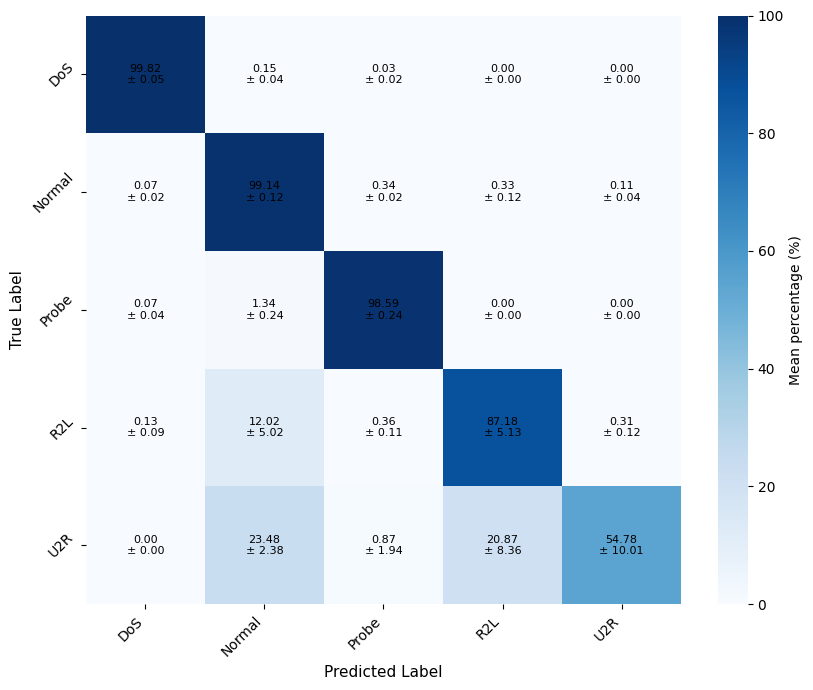

Saved balanced NSL-KDD GRU five-seed normalized confusion matrix mean ± sample SD.


In [24]:
# ============================================================
# Five-seed normalized confusion matrix: mean ± sample SD
# ============================================================

# One final row-normalized matrix is plotted.
# Seed-specific normalized matrices are used internally only
# to calculate the cell-wise mean and sample SD.

labels = np.arange(
    number_of_classes
)

class_names = (
    label_encoder.classes_
)

normalized_confusion_matrices = []

for candidate in (
    representative_candidates_by_model[
        "GRU"
    ]
):

    seed_predictions = (
        candidate[
            "Predictions"
        ]
    )

    seed_cm = confusion_matrix(
        y_test,
        seed_predictions,
        labels=labels,
    )

    row_totals = seed_cm.sum(
        axis=1,
        keepdims=True,
    )

    seed_cm_normalized = np.divide(
        seed_cm,
        row_totals,

        out=np.zeros_like(
            seed_cm,
            dtype=float,
        ),

        where=row_totals != 0,
    )

    normalized_confusion_matrices.append(
        seed_cm_normalized
    )


normalized_confusion_matrices = np.stack(
    normalized_confusion_matrices,
    axis=0,
)

if normalized_confusion_matrices.shape[0] != len(
    RUN_SEEDS
):
    raise ValueError(
        "The number of normalized confusion matrices "
        "does not match the five final-run seeds."
    )


mean_cm = np.mean(
    normalized_confusion_matrices,
    axis=0,
)

sd_cm = np.std(
    normalized_confusion_matrices,
    axis=0,
    ddof=1,
)

mean_cm_pct = mean_cm * 100.0
sd_cm_pct = sd_cm * 100.0


mean_cm_df = pd.DataFrame(
    mean_cm_pct,
    index=class_names,
    columns=class_names,
)

sd_cm_df = pd.DataFrame(
    sd_cm_pct,
    index=class_names,
    columns=class_names,
)

mean_cm_df.index.name = "True_Label"
mean_cm_df.columns.name = "Predicted_Label"

sd_cm_df.index.name = "True_Label"
sd_cm_df.columns.name = "Predicted_Label"


mean_cm_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_normalized_confusion_matrix_5_seed_mean.csv"
)

sd_cm_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_normalized_confusion_matrix_5_seed_sd.csv"
)


mean_sd_table = pd.DataFrame(
    index=class_names,
    columns=class_names,
    dtype=object,
)

for i in range(
    number_of_classes
):
    for j in range(
        number_of_classes
    ):

        mean_sd_table.iloc[
            i,
            j,
        ] = (
            f"{mean_cm_pct[i, j]:.2f} "
            f"± {sd_cm_pct[i, j]:.2f}"
        )


mean_sd_table.index.name = "True_Label"
mean_sd_table.columns.name = "Predicted_Label"

mean_sd_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_normalized_confusion_matrix_5_seed_mean_sd.csv"
)


plt.figure(
    figsize=(8.5, 7.0)
)

ax = sns.heatmap(
    mean_cm_pct,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=100,
    cbar_kws={
        "label": "Mean percentage (%)"
    },
)

for i in range(
    number_of_classes
):
    for j in range(
        number_of_classes
    ):

        ax.text(
            j + 0.5,
            i + 0.5,

            (
                f"{mean_cm_pct[i, j]:.2f}"
                f"\n± {sd_cm_pct[i, j]:.2f}"
            ),

            ha="center",
            va="center",
            fontsize=8,
        )


plt.xlabel(
    "Predicted Label",
    fontsize=11,
)

plt.ylabel(
    "True Label",
    fontsize=11,
)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.yticks(
    rotation=45,
)

plt.tight_layout()


plt.savefig(
    REPORT_OUTPUT_DIRECTORY
    / "gru_normalized_confusion_matrix_5_seed_mean_sd.pdf",
    bbox_inches="tight",
)

plt.savefig(
    REPORT_OUTPUT_DIRECTORY
    / "gru_normalized_confusion_matrix_5_seed_mean_sd.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(
    "Saved balanced NSL-KDD GRU five-seed normalized "
    "confusion matrix mean ± sample SD."
)


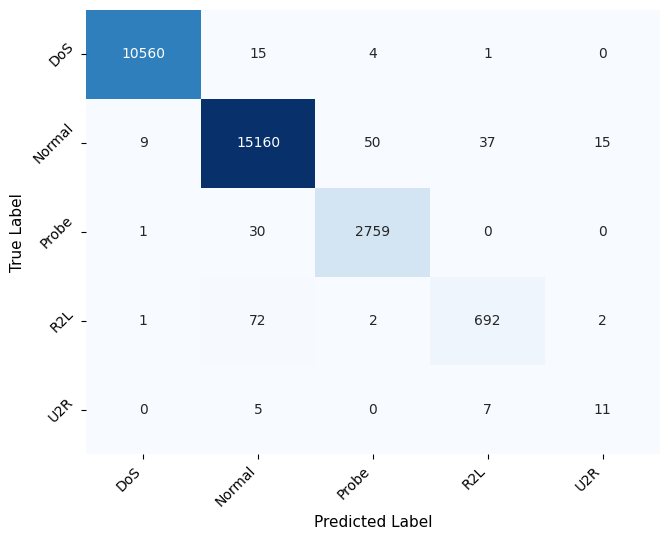

,Model,Representative_Run,Representative_Seed,Representative_F1_macro,Five_Run_Mean_F1_macro
0,GRU,2,43,0.86515,0.864295


All five-run GRU outputs were saved:


In [25]:
representative_run_records = []


for model_name in ["GRU"]:
    candidates = (
        representative_candidates_by_model[
            model_name
        ]
    )

    model_mean_f1 = float(
        all_run_results.loc[
            all_run_results[
                "Model"
            ] == model_name,
            "F1_macro",
        ].mean()
    )

    representative = min(
        candidates,
        key=lambda item: abs(
            item["F1_macro"]
            - model_mean_f1
        ),
    )

    representative_run_records.append(
        {
            "Model": model_name,
            "Representative_Run": (
                representative["Run"]
            ),
            "Representative_Seed": (
                representative["Seed"]
            ),
            "Representative_F1_macro": (
                representative[
                    "F1_macro"
                ]
            ),
            "Five_Run_Mean_F1_macro": (
                model_mean_f1
            ),
        }
    )

    output_stem = (
        REPORT_OUTPUT_DIRECTORY
        / (
            f"{model_name.lower()}_"
            "representative_confusion_matrix"
        )
    )

    plot_publication_confusion_matrix(
        y_test,
        representative[
            "Predictions"
        ],
        output_stem,
    )

    representative_report = (
        classification_report(
            y_test,
            representative[
                "Predictions"
            ],
            labels=np.arange(
                number_of_classes
            ),
            target_names=(
                label_encoder.classes_
            ),
            output_dict=True,
            zero_division=0,
        )
    )

    pd.DataFrame(
        representative_report
    ).transpose().to_csv(
        REPORT_OUTPUT_DIRECTORY
        / (
            f"{model_name.lower()}_"
            "representative_classification_report.csv"
        )
    )


# Keep the original result-variable name.
representative_runs = pd.DataFrame(
    representative_run_records
)

representative_runs.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "representative_runs.csv",
    index=False,
)


display(
    representative_runs
)

print(
    "All five-run GRU outputs were saved:"
)


#### Offline classifier-only inference timing from saved GRU models

In [ ]:
# ============================================================
# Offline classifier-only inference timing from saved GRU models
# ============================================================

# This cell can be rerun later without retraining.
# Timing excludes preprocessing and model loading.

OFFLINE_WARMUP_RUNS = 3
OFFLINE_TIMING_REPETITIONS = 5

offline_X_test = np.load(
    REPORT_OUTPUT_DIRECTORY
    / "X_test_model_input.npy"
)

offline_timing_rows = []
offline_seed_summary_rows = []


for run_number, seed in enumerate(
    RUN_SEEDS,
    start=1,
):

    model_path = (
        REPORT_OUTPUT_DIRECTORY
        / f"GRU_Seed_{run_number}"
        / f"gru_seed_{seed}.keras"
    )

    if not model_path.exists():
        raise FileNotFoundError(
            f"Saved GRU model not found: "
            f"{model_path}"
        )


    offline_model = (
        tf.keras.models.load_model(
            model_path,
            compile=False,
        )
    )


    warmup_size = min(
        1024,
        len(offline_X_test),
    )


    for _ in range(
        OFFLINE_WARMUP_RUNS
    ):

        offline_model.predict(
            offline_X_test[
                :warmup_size
            ],
            verbose=0,
        )


    seed_times = []


    for repetition in range(
        1,
        OFFLINE_TIMING_REPETITIONS + 1,
    ):

        start_time = (
            time.perf_counter()
        )

        offline_model.predict(
            offline_X_test,
            verbose=0,
        )

        elapsed_time = (
            time.perf_counter()
            - start_time
        )

        seed_times.append(
            elapsed_time
        )


        offline_timing_rows.append(
            {
                "Run":
                    run_number,

                "Seed":
                    seed,

                "Repetition":
                    repetition,

                "Inference_Time_s":
                    elapsed_time,

                "Latency_ms_per_sample":
                    (
                        elapsed_time
                        / len(
                            offline_X_test
                        )
                        * 1000.0
                    ),

                "Throughput_samples_per_s":
                    (
                        len(
                            offline_X_test
                        )
                        / elapsed_time
                    ),
            }
        )


    seed_mean_time = float(
        np.mean(
            seed_times
        )
    )


    offline_seed_summary_rows.append(
        {
            "Run":
                run_number,

            "Seed":
                seed,

            "Mean_Inference_Time_s":
                seed_mean_time,

            "SD_Inference_Time_s":
                float(
                    np.std(
                        seed_times,
                        ddof=1,
                    )
                ),

            "Mean_Latency_ms_per_sample":
                (
                    seed_mean_time
                    / len(
                        offline_X_test
                    )
                    * 1000.0
                ),

            "Mean_Throughput_samples_per_s":
                (
                    len(
                        offline_X_test
                    )
                    / seed_mean_time
                ),
        }
    )


    del offline_model
    gc.collect()
    tf.keras.backend.clear_session()


offline_timing_repetitions_df = (
    pd.DataFrame(
        offline_timing_rows
    )
)

offline_timing_per_seed_df = (
    pd.DataFrame(
        offline_seed_summary_rows
    )
)


offline_timing_repetitions_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "offline_inference_timing_repetitions.csv",
    index=False,
)

offline_timing_per_seed_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "offline_inference_timing_per_seed.csv",
    index=False,
)


summary_rows = []


for (
    metric_column,
    metric_name,
) in [
    (
        "Mean_Inference_Time_s",
        "Inference_Time_s",
    ),
    (
        "Mean_Latency_ms_per_sample",
        "Latency_ms_per_sample",
    ),
    (
        "Mean_Throughput_samples_per_s",
        "Throughput_samples_per_s",
    ),
]:

    values = (
        offline_timing_per_seed_df[
            metric_column
        ].to_numpy(
            dtype=float
        )
    )

    summary_rows.append(
        {
            "Metric":
                metric_name,

            "Mean":
                float(
                    np.mean(
                        values
                    )
                ),

            "SD":
                float(
                    np.std(
                        values,
                        ddof=1,
                    )
                ),

            "N_Seeds":
                len(
                    RUN_SEEDS
                ),
        }
    )


offline_summary_df = pd.DataFrame(
    summary_rows
)

offline_summary_df[
    "Mean ± SD"
] = offline_summary_df.apply(
    lambda row: (
        f"{row['Mean']:.6f} ± "
        f"{row['SD']:.6f}"
    ),
    axis=1,
)


offline_summary_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "offline_inference_timing_summary.csv",
    index=False,
)


print(
    "Offline balanced NSL-KDD GRU inference timing completed."
)

display(
    offline_timing_per_seed_df
)

display(
    offline_summary_df
)
